In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np

In [2]:
(X_train , y_train) , (X_test , y_test) = keras.datasets.mnist.load_data()

In [3]:
len(X_train), len(X_test)

(60000, 10000)

In [4]:
X_train.shape , X_train[0].shape

((60000, 28, 28), (28, 28))

In [5]:
# scale Xs for better accuracy by converting the pexel range from (0 , 255) to (0,1")
X_train = X_train / 255
X_test = X_test / 255

In [6]:
X_train.shape , X_test.shape , X_train[0].shape , X_test[0].shape , len(X_train) 

((60000, 28, 28), (10000, 28, 28), (28, 28), (28, 28), 60000)

In [7]:
X_train_flatten = X_train.reshape(len(X_train) , 28* 28)
X_test_flatten  = X_test.reshape(len(X_test) , 28* 28)

# Simple Nueral Network with no hidden layer

In [8]:
model = keras.Sequential ([
    keras.layers.Dense( 10 , input_shape = (28*28 , ) , activation='sigmoid' )
])

C:\Users\Humam\anaconda3\envs\dfds\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model.compile(
    optimizer="adam" , 
    loss= 'sparse_categorical_crossentropy' , 
    metrics = ['accuracy']
    
)
model.fit(X_train_flatten , y_train , epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8796 - loss: 0.4657
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9151 - loss: 0.3036
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9214 - loss: 0.2829
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9235 - loss: 0.2734
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9259 - loss: 0.2671


In [10]:
model.evaluate(X_test_flatten , y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9254 - loss: 0.2691


[0.2691250145435333, 0.9254000186920166]

In [11]:
y_predicted = model.predict(X_test_flatten)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


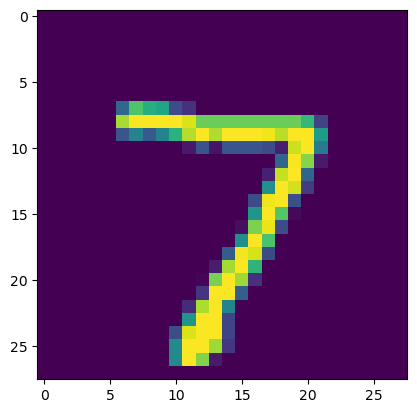

In [12]:
plt.imshow(X_test[0])

In [13]:
y_predicted[0]

array([2.16670576e-02, 6.27542420e-07, 5.07853553e-02, 9.70419466e-01,
       2.84260348e-03, 1.36685342e-01, 1.51047800e-06, 9.99751270e-01,
       1.09587856e-01, 6.73316240e-01], dtype=float32)

In [14]:
np.argmax(y_predicted[0])

np.int64(7)

In [15]:
y_predicted_labels = [np.argmax(i) for i in y_predicted]

In [16]:
from tensorflow.math import confusion_matrix
cm = confusion_matrix(labels=y_test , predictions=y_predicted_labels)
cm

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 962,    0,    0,    2,    0,    5,    7,    2,    2,    0],
       [   0, 1118,    3,    2,    0,    1,    4,    2,    5,    0],
       [   6,   11,  909,   24,    6,    5,   13,    9,   44,    5],
       [   2,    0,   11,  930,    0,   28,    2,    9,   20,    8],
       [   1,    2,    2,    2,  910,    0,   13,    3,    9,   40],
       [   7,    3,    1,   35,    8,  779,   17,    5,   31,    6],
       [   8,    3,    3,    1,    7,   12,  919,    2,    3,    0],
       [   1,    9,   18,   12,    8,    0,    0,  941,    3,   36],
       [   7,   14,    6,   26,    9,   29,    9,    8,  857,    9],
       [  10,    8,    1,   11,   22,    8,    0,   14,    6,  929]],
      dtype=int32)>

Text(95.72222222222221, 0.5, 'Predicted')

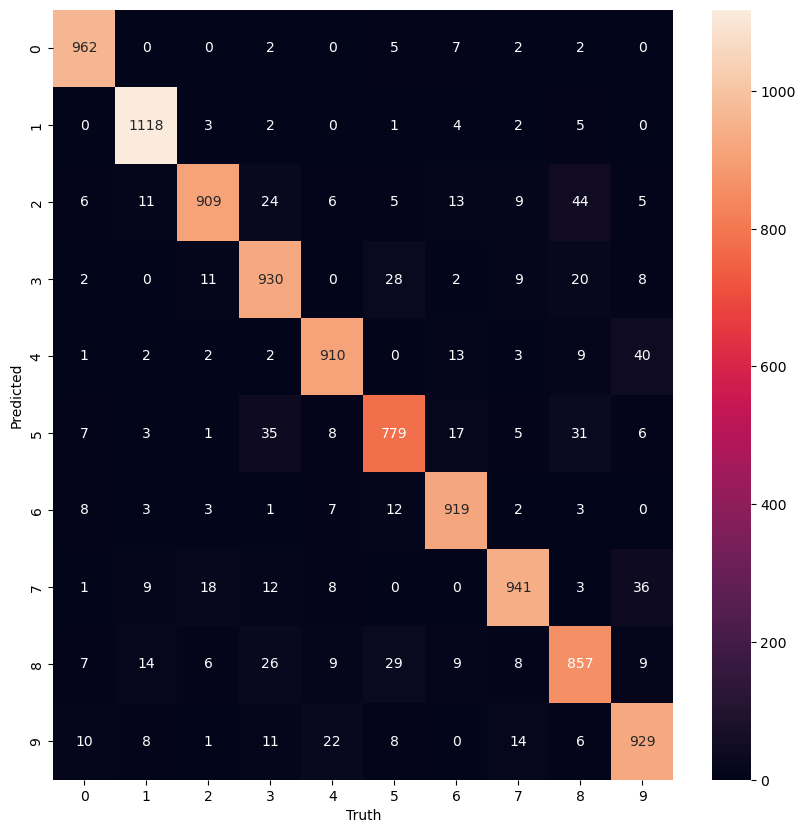

In [17]:
import seaborn as sns
plt.figure(figsize=(10,10))
sns.heatmap(cm , annot=True , fmt='d')
plt.xlabel("Truth")
plt.ylabel("Predicted")

In [18]:
model2 = keras.Sequential([
    keras.layers.Dense( 1000 , input_shape = (28*28 , ) , activation='relu'),
    keras.layers.Dense( 1000 , activation='relu'),
    keras.layers.Dense( 1000 , activation='sigmoid'),
    keras.layers.Dense( 10 , activation='sigmoid')
])

model2.compile(
    optimizer="adam",
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

C:\Users\Humam\anaconda3\envs\dfds\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
model2.fit(X_train_flatten , y_train , epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 48s 25ms/step - accuracy: 0.9397 - loss: 0.1991
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 47s 25ms/step - accuracy: 0.9731 - loss: 0.0878
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 45s 24ms/step - accuracy: 0.9803 - loss: 0.0635
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 46s 25ms/step - accuracy: 0.9848 - loss: 0.0496
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 45s 24ms/step - accuracy: 0.9878 - loss: 0.0402


In [102]:
model2.evaluate(X_test_flatten , y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9630 - loss: 0.1181


[0.1180662140250206, 0.9629999995231628]

In [103]:
y_predicted_2 = model2.predict(X_test_flatten)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [104]:
y_predicte_labels_2 = [np.argmax(i) for i in y_predicted_2]

Text(0.5, 80.7222222222222, 'Predicted')

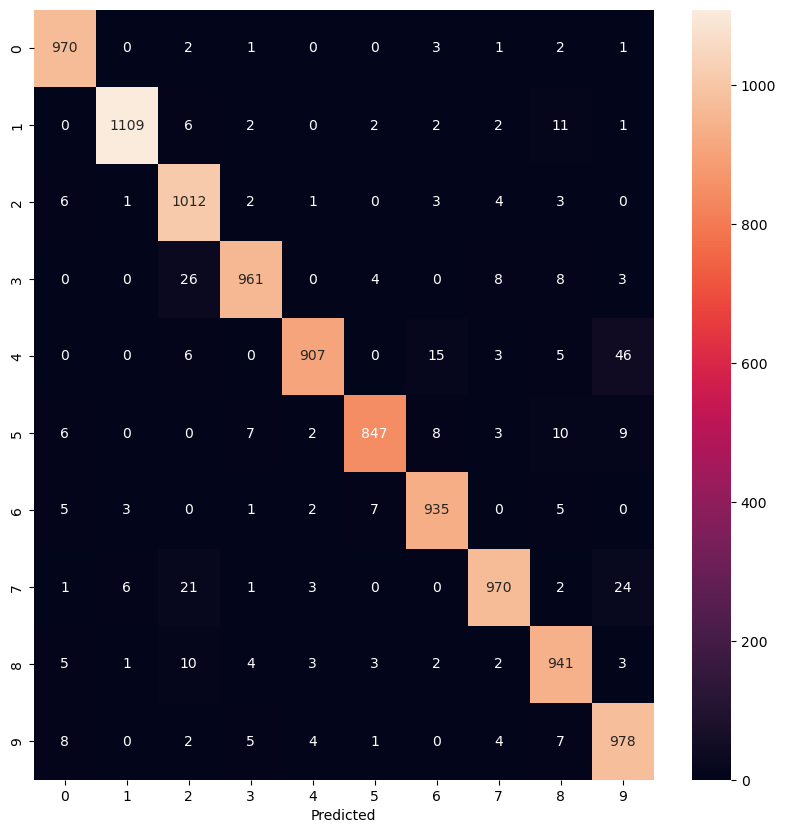

In [106]:
cm2 = confusion_matrix(labels=y_test , predictions=y_predicte_labels_2)
plt.figure(figsize=(10,10))
sns.heatmap(cm2 , annot=True , fmt='d')
plt.xlabel("Truth")
plt.xlabel("Predicted")